In [2]:
import pandas as pd

In [3]:
dataset = pd.read_csv("cardekho.csv")


In [4]:
print(dataset.columns)

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power',
       'seats'],
      dtype='str')


In [5]:
X = dataset.drop('selling_price', axis=1)
y = dataset['selling_price']

print(X.head())
print(y.head())

                           name  year  km_driven    fuel seller_type  \
0        Maruti Swift Dzire VDI  2014     145500  Diesel  Individual   
1  Skoda Rapid 1.5 TDI Ambition  2014     120000  Diesel  Individual   
2      Honda City 2017-2020 EXi  2006     140000  Petrol  Individual   
3     Hyundai i20 Sportz Diesel  2010     127000  Diesel  Individual   
4        Maruti Swift VXI BSIII  2007     120000  Petrol  Individual   

  transmission         owner  mileage(km/ltr/kg)  engine max_power  seats  
0       Manual   First Owner               23.40  1248.0        74    5.0  
1       Manual  Second Owner               21.14  1498.0    103.52    5.0  
2       Manual   Third Owner               17.70  1497.0        78    5.0  
3       Manual   First Owner               23.00  1396.0        90    5.0  
4       Manual   First Owner               16.10  1298.0      88.2    5.0  
0    450000
1    370000
2    158000
3    225000
4    130000
Name: selling_price, dtype: int64


In [6]:
print(dataset.isnull().sum())
print("Duplicates:", dataset.duplicated().sum())

name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64
Duplicates: 1202


In [7]:
dataset['max_power'] = pd.to_numeric(dataset['max_power'], errors='coerce')

In [8]:
dataset['max_power'] = dataset['max_power'].fillna(dataset['max_power'].mean())
dataset['seats'] = dataset['seats'].fillna(dataset['seats'].mean())

dataset = dataset.drop_duplicates()

In [9]:
print(dataset.isnull().sum())
print("Duplicates:", dataset.duplicated().sum())

name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    208
engine                208
max_power               0
seats                   0
dtype: int64
Duplicates: 0


In [10]:
dataset['mileage(km/ltr/kg)'] = dataset['mileage(km/ltr/kg)'].fillna(dataset['mileage(km/ltr/kg)'].mean())
dataset['engine'] = dataset['engine'].fillna(dataset['engine'].mean())

dataset['max_power'] = pd.to_numeric(dataset['max_power'], errors='coerce')
dataset['max_power'] = dataset['max_power'].fillna(dataset['max_power'].mean())

dataset['seats'] = dataset['seats'].fillna(dataset['seats'].mean())

dataset = dataset.drop_duplicates()

print(dataset.isnull().sum())
print("Duplicates:", dataset.duplicated().sum())

name                  0
year                  0
selling_price         0
km_driven             0
fuel                  0
seller_type           0
transmission          0
owner                 0
mileage(km/ltr/kg)    0
engine                0
max_power             0
seats                 0
dtype: int64
Duplicates: 0


In [11]:
print(dataset.dtypes)

name                      str
year                    int64
selling_price           int64
km_driven               int64
fuel                      str
seller_type               str
transmission              str
owner                     str
mileage(km/ltr/kg)    float64
engine                float64
max_power             float64
seats                 float64
dtype: object


In [12]:
print("Fuel:", dataset['fuel'].unique())
print("Seller Type:", dataset['seller_type'].unique())
print("Transmission:", dataset['transmission'].unique())
print("Owner:", dataset['owner'].unique())
print("Number of car names:", dataset['name'].nunique())

Fuel: <ArrowStringArray>
['Diesel', 'Petrol', 'LPG', 'CNG']
Length: 4, dtype: str
Seller Type: <ArrowStringArray>
['Individual', 'Dealer', 'Trustmark Dealer']
Length: 3, dtype: str
Transmission: <ArrowStringArray>
['Manual', 'Automatic']
Length: 2, dtype: str
Owner: <ArrowStringArray>
[         'First Owner',         'Second Owner',          'Third Owner',
 'Fourth & Above Owner',       'Test Drive Car']
Length: 5, dtype: str
Number of car names: 2058


In [13]:
dataset = dataset.drop('name', axis=1)

dataset = pd.get_dummies(
    dataset,
    columns=['fuel', 'seller_type', 'transmission', 'owner'],
    drop_first=True
)

print(dataset.head())

   year  selling_price  km_driven  mileage(km/ltr/kg)  engine  max_power  \
0  2014         450000     145500               23.40  1248.0      74.00   
1  2014         370000     120000               21.14  1498.0     103.52   
2  2006         158000     140000               17.70  1497.0      78.00   
3  2010         225000     127000               23.00  1396.0      90.00   
4  2007         130000     120000               16.10  1298.0      88.20   

   seats  fuel_Diesel  fuel_LPG  fuel_Petrol  seller_type_Individual  \
0    5.0         True     False        False                    True   
1    5.0         True     False        False                    True   
2    5.0        False     False         True                    True   
3    5.0         True     False        False                    True   
4    5.0        False     False         True                    True   

   seller_type_Trustmark Dealer  transmission_Manual  \
0                         False                 True  

In [14]:
X = dataset.drop('selling_price', axis=1)
y = dataset['selling_price']

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5540, 16)
Testing data: (1386, 16)


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training scaled shape:", X_train_scaled.shape)
print("Testing scaled shape:", X_test_scaled.shape)

Training scaled shape: (5540, 16)
Testing scaled shape: (1386, 16)


In [17]:
Q1 = dataset['selling_price'].quantile(0.25)
Q3 = dataset['selling_price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = dataset[
    (dataset['selling_price'] < lower_bound) |
    (dataset['selling_price'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Number of outliers:", len(outliers))

Q1: 250000.0
Q3: 633500.0
IQR: 383500.0
Number of outliers: 328


In [18]:
dataset = dataset[
    (dataset['selling_price'] >= lower_bound) &
    (dataset['selling_price'] <= upper_bound)
]

print("Dataset size after removing outliers:", dataset.shape)


Dataset size after removing outliers: (6598, 17)


In [19]:
X = dataset.drop('selling_price', axis=1)
y = dataset['selling_price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5278, 16)
Testing data: (1320, 16)


In [21]:
median_price = dataset['selling_price'].median()

dataset['price_category'] = dataset['selling_price'].apply(
    lambda price: 'High Price' if price >= median_price else 'Low Price'
)

print("Median price:", median_price)
print(dataset['price_category'].value_counts())

Median price: 399000.0
price_category
High Price    3304
Low Price     3294
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_class = dataset.drop(
    columns=['selling_price', 'price_category']
)
y_class = dataset['price_category']

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class, y_class, test_size=0.20,
    random_state=42, stratify=y_class
)

scaler_class = StandardScaler()

X_train_class_scaled = scaler_class.fit_transform(X_train_class)
X_test_class_scaled = scaler_class.transform(X_test_class)

print("Training:", X_train_class.shape)
print("Testing:", X_test_class.shape)


Training: (5278, 16)
Testing: (1320, 16)


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

log_model = LogisticRegression(max_iter=2000)
log_model.fit(X_train_class_scaled, y_train_class)

log_pred = log_model.predict(X_test_class_scaled)

print("Accuracy:", accuracy_score(y_test_class, log_pred))
print("Precision:", precision_score(y_test_class, log_pred, pos_label='High Price'))
print("Recall:", recall_score(y_test_class, log_pred, pos_label='High Price'))
print("F1-score:", f1_score(y_test_class, log_pred, pos_label='High Price'))

Accuracy: 0.8621212121212121
Precision: 0.856929955290611
Recall: 0.869894099848714
F1-score: 0.8633633633633634


In [24]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_class_scaled, y_train_class)

knn_pred = knn_model.predict(X_test_class_scaled)

print("Accuracy:", accuracy_score(y_test_class, knn_pred))
print("Precision:", precision_score(y_test_class, knn_pred, pos_label='High Price'))
print("Recall:", recall_score(y_test_class, knn_pred, pos_label='High Price'))
print("F1-score:", f1_score(y_test_class, knn_pred, pos_label='High Price'))

Accuracy: 0.8651515151515151
Precision: 0.8435277382645804
Recall: 0.897125567322239
F1-score: 0.8695014662756598


In [25]:
from sklearn.svm import SVC

svm_model = SVC(kernel='rbf')
svm_model.fit(X_train_class_scaled, y_train_class)

svm_pred = svm_model.predict(X_test_class_scaled)

print("Accuracy:", accuracy_score(y_test_class, svm_pred))
print("Precision:", precision_score(y_test_class, svm_pred, pos_label='High Price'))
print("Recall:", recall_score(y_test_class, svm_pred, pos_label='High Price'))
print("F1-score:", f1_score(y_test_class, svm_pred, pos_label='High Price'))

Accuracy: 0.8848484848484849
Precision: 0.8759231905465288
Recall: 0.897125567322239
F1-score: 0.8863976083707026


In [26]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_class, y_train_class)

dt_pred = dt_model.predict(X_test_class)

print("Accuracy:", accuracy_score(y_test_class, dt_pred))
print("Precision:", precision_score(y_test_class, dt_pred, pos_label='High Price'))
print("Recall:", recall_score(y_test_class, dt_pred, pos_label='High Price'))
print("F1-score:", f1_score(y_test_class, dt_pred, pos_label='High Price'))

Accuracy: 0.8696969696969697
Precision: 0.8600883652430045
Recall: 0.8835098335854765
F1-score: 0.8716417910447761


In [27]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_class, y_train_class)

rf_pred = rf_model.predict(X_test_class)

print("Accuracy:", accuracy_score(y_test_class, rf_pred))
print("Precision:", precision_score(y_test_class, rf_pred, pos_label='High Price'))
print("Recall:", recall_score(y_test_class, rf_pred, pos_label='High Price'))
print("F1-score:", f1_score(y_test_class, rf_pred, pos_label='High Price'))

Accuracy: 0.9022727272727272
Precision: 0.8982035928143712
Recall: 0.9077155824508321
F1-score: 0.9029345372460497


In [28]:
import pandas as pd

predictions = {
    "Logistic Regression": log_pred,
    "KNN": knn_pred,
    "SVM": svm_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_class, pred),
        "Precision": precision_score(y_test_class, pred, pos_label="High Price"),
        "Recall": recall_score(y_test_class, pred, pos_label="High Price"),
        "F1-score": f1_score(y_test_class, pred, pos_label="High Price")
    })

comparison = pd.DataFrame(results)

print(comparison.round(4))
print("\nBest Model:", comparison.loc[comparison["Accuracy"].idxmax(), "Model"])

                 Model  Accuracy  Precision  Recall  F1-score
0  Logistic Regression    0.8621     0.8569  0.8699    0.8634
1                  KNN    0.8652     0.8435  0.8971    0.8695
2                  SVM    0.8848     0.8759  0.8971    0.8864
3        Decision Tree    0.8697     0.8601  0.8835    0.8716
4        Random Forest    0.9023     0.8982  0.9077    0.9029

Best Model: Random Forest


In [29]:
from sklearn.metrics import confusion_matrix

print("Best Model: Random Forest")
print("Confusion Matrix:")
print(confusion_matrix(y_test_class, rf_pred))

print("\nPredicted Categories:")
print(pd.Series(rf_pred).value_counts())

Best Model: Random Forest
Confusion Matrix:
[[600  61]
 [ 68 591]]

Predicted Categories:
High Price    668
Low Price     652
Name: count, dtype: int64


In [30]:
from sklearn.preprocessing import StandardScaler

cluster_features = dataset[
    ['year', 'km_driven', 'mileage(km/ltr/kg)',
     'engine', 'max_power', 'selling_price']
].copy()

cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_features)

print("Clustering data shape:", cluster_scaled.shape)
print(cluster_features.head())

Clustering data shape: (6598, 6)
   year  km_driven  mileage(km/ltr/kg)  engine  max_power  selling_price
0  2014     145500               23.40  1248.0      74.00         450000
1  2014     120000               21.14  1498.0     103.52         370000
2  2006     140000               17.70  1497.0      78.00         158000
3  2010     127000               23.00  1396.0      90.00         225000
4  2007     120000               16.10  1298.0      88.20         130000


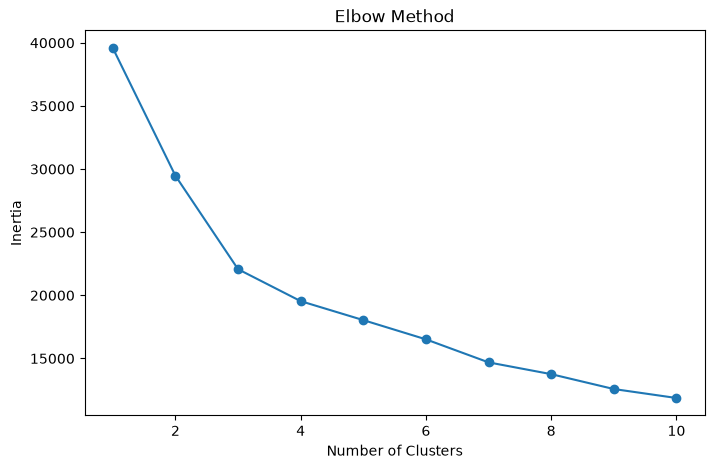

In [31]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(cluster_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

In [32]:
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)

dataset['Cluster'] = kmeans_final.fit_predict(cluster_scaled)

print("Number of cars in each cluster:")
print(dataset['Cluster'].value_counts().sort_index())

Number of cars in each cluster:
Cluster
0    1010
1    3144
2    2444
Name: count, dtype: int64


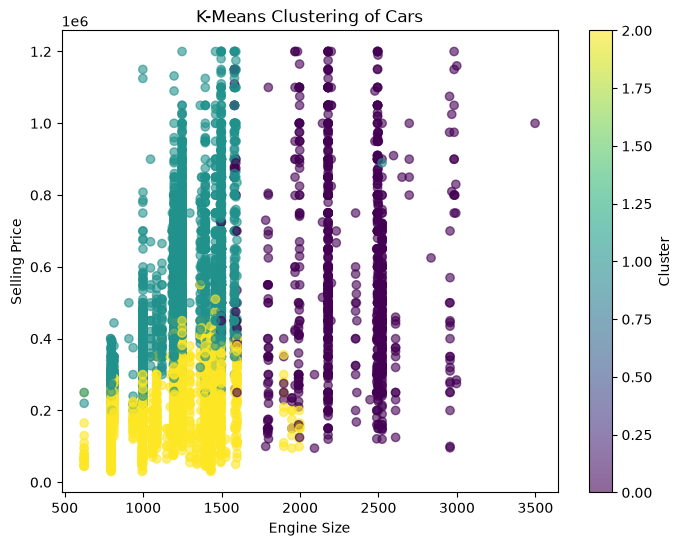

In [33]:
plt.figure(figsize=(8, 6))

plt.scatter(
    dataset['engine'],
    dataset['selling_price'],
    c=dataset['Cluster'],
    cmap='viridis',
    alpha=0.6
)

plt.title("K-Means Clustering of Cars")
plt.xlabel("Engine Size")
plt.ylabel("Selling Price")
plt.colorbar(label="Cluster")
plt.show()

In [34]:
cluster_summary = dataset.groupby('Cluster')[
    ['selling_price', 'engine', 'km_driven', 'year', 'max_power']
].mean().round(2)

cluster_summary['Number of Cars'] = dataset.groupby('Cluster').size()

print(cluster_summary)

         selling_price   engine  km_driven     year  max_power  Number of Cars
Cluster                                                                       
0            582692.04  2284.81  114280.22  2012.16      114.2            1010
1            561635.77  1253.17   52022.06  2016.26       83.9            3144
2            207662.00  1198.16   89157.38  2009.86       71.5            2444
